# Does the time step change the ESC results?

**Question for JJ.** All sweeps in this repository use a time step of $dt$ = 0.01 s. With dither frequencies of
8 to 10 Hz the ESC then converges about twice as fast as the averaged (continuous-time) formula predicts, while
the energy lost to the dither is not affected. Should the model be read as a **digital ESC sampled at 100 Hz** (then
$dt$ = 0.01 s is right and the convergence formula needs its sampled version), or as **continuous-time ESC** (then
$dt$ must be smaller, about 0.001 s, for 8 to 10 Hz dithers)?

This notebook shows the effect in three steps:

1. the same ESC loop at five time steps, with the gain chosen so that the continuous formula predicts the same
   convergence rate at every dither frequency;
2. the measured rate compared with the continuous formula and with the same formula for the sampled loop;
3. the energy lost to the dither, and the energy lost while converging, at each time step.

Everything uses `Tools/esc_sim.py`, the simulator behind all Python data sets (it reproduces the MATLAB sweeps).

In [1]:
# Shared tools (plot style, model constants, averaged-ESC formulas) live in Tools/ at the repository root
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'Tools' / 'esc_tools.py').exists())
sys.path.insert(0, str(ROOT / 'Tools'))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import esc_tools as esc
import esc_sim as sim

esc.apply_style()   # one plot style for every notebook in this repository

## 1. Set-up

**Averaged formula.** For small gains the estimate approaches the best ratio exponentially,
$\mathrm{d}\hat r/\mathrm{d}t \approx -\lambda_\mathrm{avg} (\hat r - r_\mathrm{ideal})$, with

$$\lambda_\mathrm{avg} = 2 n_\mathrm{ref}^2\, k\, c(\omega), \qquad c(\omega) = \mathrm{Re}\{G(i\omega) H(i\omega)\},$$

$G = \bar\alpha/(s + \bar\alpha)$ the response of the plasma composition to the fuel ratio and $H = s/(s + \omega/\pi)$ the
high-pass filter (`esc.lam_avg`, `esc.c_factor`). Because the plasma itself lags the fuelling with rate $\bar\alpha$, the
slow loop is second order, $s^2 + \bar\alpha s + \bar\alpha \lambda_\mathrm{avg} = 0$, and its slow root is the predicted
convergence rate.

**Runs.** Plant with $r_\mathrm{ideal}$ = 0.525 (no drift), starting from a plasma already running at $r$ = 0.5 with
$\hat r$ = 0.5. Dither amplitude $a$ = 0.1. For each dither frequency $f$ = 0.5 to 10 Hz the gain $k$ is chosen so that
$\lambda_\mathrm{avg}$ = 0.03 s$^{-1}$: the continuous formula predicts **the same** convergence rate for every $f$ (well
below critical damping, $\bar\alpha/4$ = 0.15 s$^{-1}$, so the approach is a clean exponential). The same runs are repeated
with $dt$ = 0.01, 0.005, 0.002, 0.001 and 0.0005 s, for 300 s each.

**Rate measurement.** $\hat r$ is averaged over whole dither periods (about 1 s) and fitted between 10 and 290 s with
$\hat r(t) = \hat r_\infty - A e^{-s t}$. The end value $\hat r_\infty$ is a free parameter, because $\hat r$ settles slightly
above $r_\mathrm{ideal}$ (see the end of Section 2).

In [2]:
ALPHA_BAR = esc.ALPHA_BAR
FREQUENCIES = np.array([0.5, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10.0])     # dither frequency [Hz]
LAM_TARGET = 0.03                                                # continuous-time averaged rate [1/s]
GAINS = LAM_TARGET / (2 * esc.N_REF ** 2 * esc.c_factor(FREQUENCIES))
TIME_STEPS = [0.01, 0.005, 0.002, 0.001, 0.0005]                 # [s]
R_IDEAL, AMPLITUDE, T_RUN, FIT_WINDOW = 0.525, 0.1, 300.0, (10.0, 290.0)


def slow_root(lam):
    """Slow root of s^2 + alpha_bar s + alpha_bar lam = 0 (overdamped loop): the predicted convergence rate."""
    return ALPHA_BAR / 2 * (1 - np.sqrt(1 - 4 * np.asarray(lam) / ALPHA_BAR))


def c_sampled(f, dt):
    """c(omega) of the loop as the simulation samples it: plant and high-pass as difference equations."""
    w = 2 * np.pi * np.asarray(f, dtype=float)
    z = np.exp(1j * w * dt)
    A = np.exp(-ALPHA_BAR * dt)
    p = np.exp(-(w / np.pi) * dt)
    G = (1 - A) / (1 - A / z)          # n[i+1] = A n[i] + (1 - A) r[i], compared with the dither at step i
    H = (1 - 1 / z) / (1 - p / z)      # y[i] = x[i] - x[i-1] + p y[i-1]
    return np.real(G * H)


def end_model(t, amplitude, rate, end):
    return end - amplitude * np.exp(-rate * (t - FIT_WINDOW[0]))


print('Gains: ' + ', '.join(f'{f:g} Hz: {k:.4f}' for f, k in zip(FREQUENCIES, GAINS)))

Gains: 0.5 Hz: 0.0013, 1 Hz: 0.0032, 2 Hz: 0.0073, 3 Hz: 0.0114, 4 Hz: 0.0155, 5 Hz: 0.0196, 6 Hz: 0.0238, 7 Hz: 0.0279, 8 Hz: 0.0320, 9 Hz: 0.0362, 10 Hz: 0.0403


In [3]:
rows, curves = [], {}
start = time.time()
for dt in TIME_STEPS:
    plant = dict(r_ideal_0=R_IDEAL, lambda_r_ideal=0.0, steady_start=0.5, dt=dt, tend=T_RUN)
    out = sim.simulate(GAINS, AMPLITUDE, FREQUENCIES, r_hat_0=0.5, return_traces=True, **plant)
    ideal_energy = sim.simulate(1, 0.1, 1, use_esc=False, fixed_ratio='ideal', **plant)['energy'][0]
    t, r_hat = out['traces']['t'], out['traces']['r_hat']
    for j, f in enumerate(FREQUENCIES):
        window = int(round(max(1, round(f)) / (f * dt)))            # whole dither periods, about 1 s
        cumulative = np.cumsum(np.concatenate([[0], r_hat[:, j]]))
        smooth = (cumulative[window:] - cumulative[:-window]) / window
        centre = t[:len(smooth)] + (window - 1) * dt / 2
        every = max(1, int(round(0.05 / dt)))                       # one point per 0.05 s
        fit = (centre >= FIT_WINDOW[0]) & (centre <= FIT_WINDOW[1])
        (amplitude, rate, end), _ = curve_fit(end_model, centre[fit][::every], smooth[fit][::every],
                                              p0=[0.02, 0.03, R_IDEAL])
        residual = np.sqrt(np.mean((smooth[fit][::every] - end_model(centre[fit][::every], amplitude, rate, end)) ** 2))
        rows.append({'dt': dt, 'f': f, 'k': GAINS[j], 'measured rate': rate, 'end offset': end - R_IDEAL,
                     'fit rms': residual, 'continuous prediction': slow_root(LAM_TARGET),
                     'sampled prediction': slow_root(2 * esc.N_REF ** 2 * GAINS[j] * c_sampled(f, dt)),
                     'shortfall': ideal_energy - out['energy'][j]})
        curves[(dt, f)] = (centre[::every], smooth[::every], end)
    print(f'dt = {dt} s done ({time.time() - start:.0f} s)')

rates = pd.DataFrame(rows)
rates['measured / continuous'] = rates['measured rate'] / rates['continuous prediction']
rates['measured / sampled'] = rates['measured rate'] / rates['sampled prediction']
print(f"Largest fit residual: {rates['fit rms'].max():.1e} (in r_hat)")

dt = 0.01 s done (10 s)
dt = 0.005 s done (31 s)
dt = 0.002 s done (82 s)
dt = 0.001 s done (184 s)
dt = 0.0005 s done (388 s)
Largest fit residual: 2.0e-06 (in r_hat)


## 2. Measured convergence rate against the formulas

**One frequency first.** At $f$ = 8 Hz: the remaining distance to the end value, $(\hat r_\infty - \hat r)/(\hat r_\infty - 0.5)$,
on a logarithmic axis, so that an exponential approach is a straight line whose slope is the rate. Dashed: the
continuous formula. With $dt$ = 0.01 s the estimate approaches its end value about twice as fast.

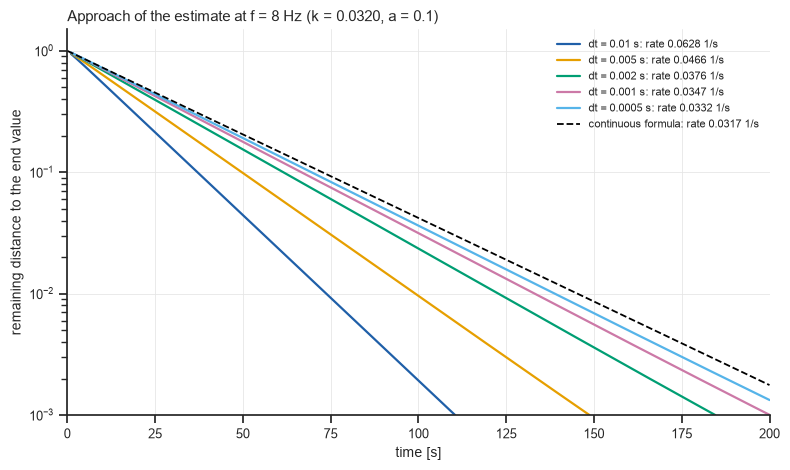

In [4]:
DEMO_F = 8.0
colors = dict(zip(TIME_STEPS, esc.CYCLE))
fig, ax = plt.subplots(figsize=(8, 4.8))
for dt in TIME_STEPS:
    centre, smooth, end = curves[(dt, DEMO_F)]
    remaining = (end - smooth) / (end - 0.5)
    shown = (centre > 1) & (remaining > 1e-3)
    rate = rates.query('dt == @dt and f == @DEMO_F')['measured rate'].iloc[0]
    ax.plot(centre[shown], remaining[shown], color=colors[dt], lw=1.6, label=f'dt = {dt:g} s: rate {rate:.4f} 1/s')
t_line = np.linspace(0, 200, 50)
ax.plot(t_line, np.exp(-slow_root(LAM_TARGET) * t_line), color='black', ls='--', lw=1.3,
        label=f'continuous formula: rate {slow_root(LAM_TARGET):.4f} 1/s')
ax.set_yscale('log'); ax.set_ylim(1e-3, 1.5); ax.set_xlim(0, 200)
ax.set_xlabel('time [s]'); ax.set_ylabel('remaining distance to the end value')
ax.set_title(f'Approach of the estimate at f = {DEMO_F:g} Hz (k = {GAINS[FREQUENCIES == DEMO_F][0]:.4f}, a = {AMPLITUDE})')
ax.legend(loc='upper right', fontsize=8)
fig.tight_layout()
plt.show()

**All frequencies.** Left: measured rate divided by the continuous prediction. Every point would be at 1 if the
continuous formula held. Right: measured rate divided by the prediction for the sampled loop, which uses the same
averaged formula with $G$ and $H$ written as the difference equations the simulation actually solves.

Measured rate / continuous prediction:


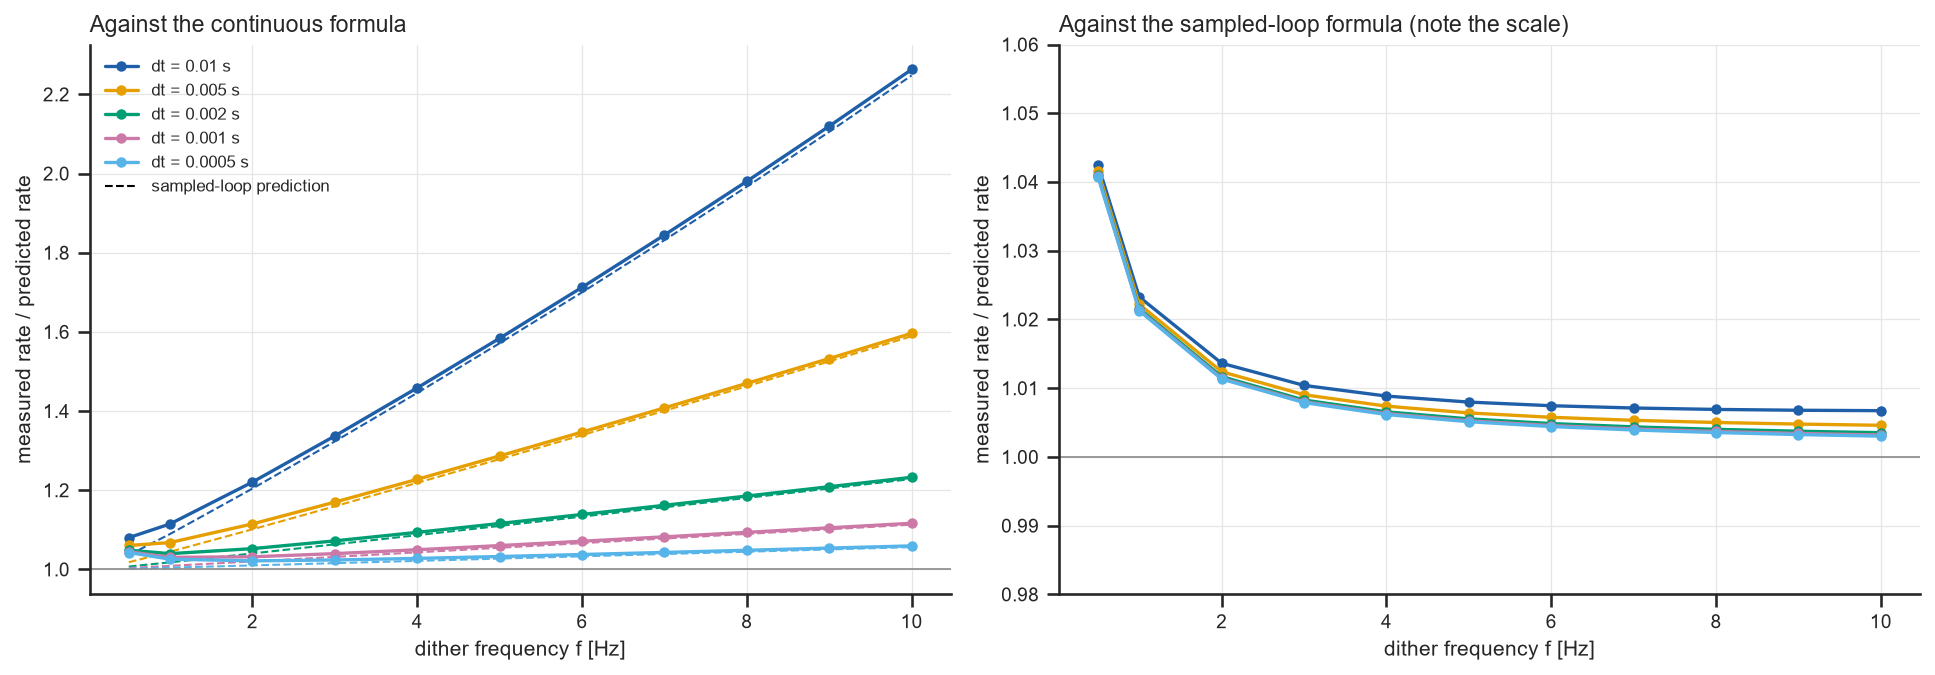

,dt = 0.0005,dt = 0.001,dt = 0.002,dt = 0.005,dt = 0.01
f,,,,,
0.5,1.043,1.045,1.049,1.060,1.080
1.0,1.026,1.030,1.040,1.068,1.115
2.0,1.021,1.032,1.052,1.115,1.220
3.0,1.024,1.040,1.072,1.170,1.337
4.0,1.028,1.050,1.094,1.228,1.459
5.0,1.033,1.060,1.116,1.287,1.584
6.0,1.038,1.071,1.139,1.347,1.713
7.0,1.043,1.082,1.162,1.408,1.845
8.0,1.048,1.094,1.185,1.470,1.980


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), dpi=150)
for dt in TIME_STEPS:
    part = rates[rates['dt'] == dt]
    axes[0].plot(part['f'], part['measured / continuous'], marker='o', ms=4, color=colors[dt], label=f'dt = {dt:g} s')
    predicted_ratio = part['sampled prediction'] / part['continuous prediction']
    axes[0].plot(part['f'], predicted_ratio, ls='--', lw=1, color=colors[dt])
    axes[1].plot(part['f'], part['measured / sampled'], marker='o', ms=4, color=colors[dt], label=f'dt = {dt:g} s')
for ax in axes:
    ax.axhline(1, color=esc.COLORS['grey'], lw=0.8)
    ax.set_xlabel('dither frequency f [Hz]')
axes[0].plot([], [], color='black', ls='--', lw=1, label='sampled-loop prediction')
axes[0].set_ylabel('measured rate / predicted rate')
axes[0].set_title('Against the continuous formula')
axes[1].set_title('Against the sampled-loop formula (note the scale)')
axes[1].set_ylim(0.98, 1.06)
axes[1].set_ylabel('measured rate / predicted rate')
axes[0].legend(loc='upper left', fontsize=8)
fig.tight_layout()
plt.show()

table = rates.pivot(index='f', columns='dt', values='measured / continuous').round(3)
table.columns = [f'dt = {c:g}' for c in table.columns]
print('Measured rate / continuous prediction:')
table

In [6]:
table = rates.pivot(index='f', columns='dt', values='measured / sampled').round(3)
table.columns = [f'dt = {c:g}' for c in table.columns]
print('Measured rate / sampled-loop prediction:')
table

Measured rate / sampled-loop prediction:


,dt = 0.0005,dt = 0.001,dt = 0.002,dt = 0.005,dt = 0.01
f,,,,,
0.5,1.041,1.041,1.041,1.042,1.042
1.0,1.021,1.021,1.022,1.022,1.023
2.0,1.011,1.011,1.012,1.012,1.014
3.0,1.008,1.008,1.008,1.009,1.010
4.0,1.006,1.006,1.007,1.007,1.009
5.0,1.005,1.005,1.006,1.006,1.008
6.0,1.004,1.005,1.005,1.006,1.007
7.0,1.004,1.004,1.004,1.005,1.007
8.0,1.004,1.004,1.004,1.005,1.007


**Why.** The useful part of the dither response is the part in phase with the demodulating sine:
$c = |GH| \cos\varphi$. Above a few Hz the plasma lags the fuelling by almost 90 degrees, so $\cos\varphi$ is small and
very sensitive to any extra phase. In the simulation the plasma state after step $i$ is compared with the dither of
step $i$, which advances the phase of the response by about $\omega\,dt/2$: 14 degrees at 8 Hz with $dt$ = 0.01 s. The
phase of $GH$ goes from $-71.7$ to $-57.7$ degrees, so $\cos\varphi$ rises by a factor 1.7, and the sampled high-pass
filter passes about 8 % more. Together the gradient estimate is about 1.9 times larger, and so is the speed. The size
of the plasma's own response, $|G|$, changes by only about 1 %, which is why the energy lost to the dither
(proportional to $|G|^2$) stays the same (Section 3).

In [7]:
w = 2 * np.pi * FREQUENCIES
G_c = ALPHA_BAR / (1j * w + ALPHA_BAR); H_c = 1j * w / (1j * w + w / np.pi)
phase_rows = {'continuous': np.degrees(np.angle(G_c * H_c))}
size_rows = {}
for dt in TIME_STEPS:
    z = np.exp(1j * w * dt); A = np.exp(-ALPHA_BAR * dt); p = np.exp(-(w / np.pi) * dt)
    G_d = (1 - A) / (1 - A / z); H_d = (1 - 1 / z) / (1 - p / z)
    phase_rows[f'dt = {dt:g}'] = np.degrees(np.angle(G_d * H_d))
    size_rows[f'|G| ratio, dt = {dt:g}'] = np.abs(G_d) / np.abs(G_c)
    size_rows[f'|H| ratio, dt = {dt:g}'] = np.abs(H_d) / np.abs(H_c)
index = pd.Index(FREQUENCIES, name='f [Hz]')
# phase of G H in degrees; the in-phase factor of the gradient estimate is cos of this
pd.DataFrame(phase_rows, index=index).round(1)

,continuous,dt = 0.01,dt = 0.005,dt = 0.002,dt = 0.001,dt = 0.0005
f [Hz],,,,,,
0.5,-61.6,-60.7,-61.2,-61.5,-61.6,-61.6
1.0,-66.9,-65.2,-66.0,-66.6,-66.8,-66.9
2.0,-69.6,-66.1,-67.8,-68.9,-69.3,-69.5
3.0,-70.5,-65.2,-67.9,-69.5,-70.0,-70.3
4.0,-71.0,-63.9,-67.4,-69.6,-70.3,-70.6
5.0,-71.3,-62.4,-66.8,-69.5,-70.4,-70.8
6.0,-71.4,-60.9,-66.1,-69.3,-70.4,-70.9
7.0,-71.6,-59.3,-65.3,-69.1,-70.3,-70.9
8.0,-71.7,-57.7,-64.6,-68.8,-70.2,-70.9


Size of the sampled plant response $|G|$ and of the sampled high-pass filter $|H|$, relative to continuous time:

In [8]:
pd.DataFrame(size_rows, index=index)[[c for t in ('0.01', '0.002', '0.0005')
                                      for c in (f'|G| ratio, dt = {t}', f'|H| ratio, dt = {t}')]].round(3)

,"|G| ratio, dt = 0.01","|H| ratio, dt = 0.01","|G| ratio, dt = 0.002","|H| ratio, dt = 0.002","|G| ratio, dt = 0.0005","|H| ratio, dt = 0.0005"
f [Hz],,,,,,
0.5,1.000,1.005,1.000,1.001,1.0,1.000
1.0,1.000,1.010,1.000,1.002,1.0,1.001
2.0,1.001,1.020,1.000,1.004,1.0,1.001
3.0,1.001,1.030,1.000,1.006,1.0,1.002
4.0,1.003,1.041,1.000,1.008,1.0,1.002
5.0,1.004,1.051,1.000,1.010,1.0,1.003
6.0,1.006,1.061,1.000,1.012,1.0,1.003
7.0,1.008,1.072,1.000,1.014,1.0,1.004
8.0,1.011,1.082,1.000,1.016,1.0,1.004


**Side finding: the estimate settles slightly above the ideal ratio.** The fitted end value $\hat r_\infty$ lies 0.0003
to 0.003 above $r_\mathrm{ideal}$ = 0.525 (largest at 1 to 2 Hz), at every time step. This offset is not caused by the time
step; it costs $T n_\mathrm{ref}^2 \cdot \text{offset}^2$, below 0.1 energy units per 100 s.

In [9]:
offsets = rates.pivot(index='f', columns='dt', values='end offset').round(5)
offsets.columns = [f'dt = {c:g}' for c in offsets.columns]
print('End value of r_hat minus r_ideal:')
offsets

End value of r_hat minus r_ideal:


,dt = 0.0005,dt = 0.001,dt = 0.002,dt = 0.005,dt = 0.01
f,,,,,
0.5,0.00052,0.00051,0.00049,0.00044,0.00035
1.0,0.00309,0.00307,0.00303,0.00293,0.00276
2.0,0.00261,0.00258,0.00253,0.00238,0.00217
3.0,0.00197,0.00194,0.00189,0.00173,0.00151
4.0,0.00156,0.00153,0.00147,0.00131,0.00111
5.0,0.00129,0.00125,0.00119,0.00104,0.00084
6.0,0.00109,0.00106,0.00100,0.00085,0.00066
7.0,0.00094,0.00091,0.00085,0.00070,0.00053
8.0,0.00083,0.00080,0.00074,0.00060,0.00044


## 3. Energy at each time step

**Energy lost to the dither.** Plant exactly at $r_\mathrm{ideal}$ = 0.5, start at 0.5, ESC with a negligible gain
($k = 10^{-7}$, so $\hat r$ stays at 0.5): everything ESC loses against $r$ = 0.5 is the dither ($a$ = 0.2, 100 s).
Compared with the formula $L_\mathrm{dith} = T n_\mathrm{ref}^2/4 \cdot 2 a^2 \bar\alpha^2/(\bar\alpha^2 + \omega^2)$ (`esc.dither_loss`).

In [10]:
loss_rows = []
for dt in TIME_STEPS:
    plant = dict(r_ideal_0=0.5, lambda_r_ideal=0.0, steady_start=0.5, dt=dt, tend=100.0)
    dithered = sim.simulate(np.full(len(FREQUENCIES), 1e-7), 0.2, FREQUENCIES, r_hat_0=0.5, **plant)
    fixed = sim.simulate(1, 0.1, 1, use_esc=False, fixed_ratio=0.5, **plant)['energy'][0]
    for f, energy in zip(FREQUENCIES, dithered['energy']):
        loss_rows.append({'dt': dt, 'f': f, 'loss': fixed - energy, 'formula': float(esc.dither_loss(0.2, f))})
losses = pd.DataFrame(loss_rows)
losses['loss / formula'] = losses['loss'] / losses['formula']
table = losses.pivot(index='f', columns='dt', values='loss / formula').round(4)
table.columns = [f'dt = {c:g}' for c in table.columns]
print('Energy lost to the dither / formula:')
table

Energy lost to the dither / formula:


,dt = 0.0005,dt = 0.001,dt = 0.002,dt = 0.005,dt = 0.01
f,,,,,
0.5,1.0163,1.0163,1.0163,1.0163,1.0164
1.0,1.0167,1.0167,1.0167,1.0168,1.0171
2.0,1.0168,1.0168,1.0169,1.0172,1.0182
3.0,1.0168,1.0169,1.0170,1.0176,1.0198
4.0,1.0169,1.0169,1.0171,1.0182,1.0220
5.0,1.0169,1.0169,1.0172,1.0189,1.0249
6.0,1.0169,1.0170,1.0173,1.0198,1.0285
7.0,1.0169,1.0170,1.0175,1.0208,1.0327
8.0,1.0169,1.0171,1.0177,1.0220,1.0376


**Energy lost while converging.** For the runs of Section 2 (plant 0.525, 300 s): the shortfall against perfect
fuelling, $E_\mathrm{ideal} - E_\mathrm{ESC}$, at the coarsest and the finest time step. It is mostly the energy lost while
$\hat r$ is still far from $r_\mathrm{ideal}$, so it scales with the convergence time and does change with $dt$.

In [11]:
short = rates.pivot(index='f', columns='dt', values='shortfall')
energy_table = pd.DataFrame({'shortfall, dt = 0.01': short[0.01], 'shortfall, dt = 0.0005': short[0.0005],
                             'ratio': short[0.01] / short[0.0005],
                             'rate ratio (0.0005 / 0.01)': rates.pivot(index='f', columns='dt', values='measured rate')
                             .pipe(lambda r: r[0.0005] / r[0.01])})
energy_table.round(3)

,"shortfall, dt = 0.01","shortfall, dt = 0.0005",ratio,rate ratio (0.0005 / 0.01)
f,,,,
0.5,8.096,8.122,0.997,0.965
1.0,2.984,3.086,0.967,0.920
2.0,1.551,1.739,0.892,0.837
3.0,1.203,1.464,0.822,0.766
4.0,1.041,1.370,0.760,0.705
5.0,0.939,1.328,0.707,0.652
6.0,0.862,1.307,0.660,0.606
7.0,0.801,1.293,0.619,0.565
8.0,0.749,1.284,0.583,0.529


## 4. Summary for JJ

- **Convergence speed depends on the time step at high dither frequencies.** With the gain set so that the continuous
  formula predicts the same rate at every frequency, the simulation with $dt$ = 0.01 s converges 1.08 times faster at
  0.5 Hz, about 1.5 times at 5 Hz, 1.98 times at 8 Hz and 2.26 times at 10 Hz. With $dt$ = 0.0005 s the factor is
  1.02 to 1.06 at every frequency, so the continuous formula is right in continuous time.
- **The cause is the phase of the sampled loop, not an error in the simulation.** The same averaged formula with the
  plant and the filters written as the difference equations of the simulation predicts every measured rate to within
  0.3 to 4 %, at every time step. Above a few Hz the plasma lags the dither by almost 90 degrees, so the in-phase part
  of the response is small and the extra phase of about $\omega\,dt/2$ (14 degrees at 8 Hz) changes it a lot.
- **The energy lost to the dither does not depend on the time step** (at most 3 % between $dt$ = 0.01 and 0.0005 s,
  and within 2 to 5 % of the formula), because it depends on the size of the response, not its phase. The energy lost
  while converging does change, in proportion to the convergence time.
- **Consequence for the results so far.** Win/loss statements and the dither-loss bound are not affected. Convergence
  times and settling times of sets with $f \gtrsim$ 3 Hz are those of an ESC sampled at 100 Hz; in continuous time they
  would be up to about twice as long at 8 to 10 Hz.
- **Question:** is the intended controller a digital ESC at 100 Hz (keep $dt$ = 0.01 s and use the sampled formula), or
  continuous-time ESC (rerun with $dt \approx$ 0.001 s, about 10 times the run time)? In a real machine the ESC would
  run at the sampling rate of the neutron diagnostic and the gas valves, which may be lower than 100 Hz; the
  effect would then be larger.